# Interactive event exploration

This tutorial builds on the static event timeline from the previous notebook. The same event frame now acts as a **master view**: click an event in the timeline and a type-specific **detail view** appears underneath it.

The explorer runs in the notebook kernel, so renderers can read lazy event data only when a user asks to see it. Install the optional dependencies with `pip install -e ".[viz]"` if needed.

In [1]:
import math

import numpy as np
import plotly.graph_objects as go
from ipywidgets import HTML
from neuralset.events import etypes

from neuralshed import viz
from neuralshed.datasets.singer_2025.study import Singer2025CursorControl
from neuralshed.datasets.utils import dataset_dir

## Load one Singer-Clark block

We use the same block as the first visualization tutorial. Its event frame contains discrete task events alongside lazy, whole-block neural and behavioral streams.

In [2]:
singer = Singer2025CursorControl(
    path=str(dataset_dir("singer_2025") / "data"),
    #query="session == 't15_day00202' and run == 'block02'",
).run()
block = singer.loc[
    (singer.session == "t15_day00202") & (singer.run == "block02")
].copy()
label = f"{block.session.iloc[0]}/{block.run.iloc[0]}"

LANES = [
    "Intertrial",
    "Stimulus",
    "Word",
    "Action",
    "SpikeCounts",
    "BandPower",
    "CursorPositionSeries",
    "TargetPositionSeries",
    "DecodedCursorVelocitySeries",
    "CursorAssistSeries",
]

print(f"{len(block)} events · {block.type.nunique()} event types · {label}")

142 events · 10 event types · t15_day00202/block02


## 1. Click an event to open its detail view

Run the cell below in a live Jupyter kernel, then click a `Word`, `Action`, or continuous-data lane. In the fixed-height top row, the sidebar's **Filter** tab controls the query, text search, visible event types, and lane order; its **View** tab controls time and the active detail view. The selected event's visualization occupies its own full-width row underneath. Text events open as readable text; position streams open as trajectories; behavioral streams open as traces; and dense arrays can open as heatmaps.

Continuous arrays remain lazy until their detail view is selected. Once a time-aware detail plot is open, zooming or panning the timeline automatically updates it to the visible time window; text and field views stay unchanged. Use **Add reference** in the View tab to create labeled, colored, draggable time lines. Time-axis views repeat every applicable line, while spatial trajectories show the corresponding filled dots.

In [3]:
explorer = viz.explore_events(
    events=singer,
    #lanes=LANES,
    label=label,
    #time_range=(0, 450),
    #top_row_height=600,
    #event_type_list_height=180,
    references=[15, 30],
)
explorer

## 2. A compact event timeline

Events of the same type share a Plotly trace, so the figure stays manageable even when the dataframe has many rows. Each plotted mark carries its zero-based dataframe row position as `customdata`; that is the stable bridge from a click back to the selected event.

In [4]:
block

,type,start,duration,timeline,subject,session,task,run,feature,frequency,...,brain_region,processing,stop,dataset_id,participant_id,text,language,context,sentence,sentence_char
866,SpikeCounts,0.00,180.01,"Singer2025CursorControl:click_enabled=False,cu...",Singer2025CursorControl/T15,t15_day00202,simultaneous_speech_and_cursor,block02,threshold_crossings,100.0,...,,,180.01,singer_2025,braingate2/T15,NaN,NaN,NaN,NaN,NaN
867,BandPower,0.00,180.01,"Singer2025CursorControl:click_enabled=False,cu...",Singer2025CursorControl/T15,t15_day00202,simultaneous_speech_and_cursor,block02,spike_band_power,100.0,...,,,180.01,singer_2025,braingate2/T15,NaN,NaN,NaN,NaN,NaN
868,CursorPositionSeries,0.00,180.01,"Singer2025CursorControl:click_enabled=False,cu...",Singer2025CursorControl/T15,t15_day00202,simultaneous_speech_and_cursor,block02,cursor_position,100.0,...,,,180.01,singer_2025,braingate2/T15,NaN,NaN,NaN,NaN,NaN
869,TargetPositionSeries,0.00,180.01,"Singer2025CursorControl:click_enabled=False,cu...",Singer2025CursorControl/T15,t15_day00202,simultaneous_speech_and_cursor,block02,target_position,100.0,...,,,180.01,singer_2025,braingate2/T15,NaN,NaN,NaN,NaN,NaN
870,DecodedCursorVelocitySeries,0.00,180.01,"Singer2025CursorControl:click_enabled=False,cu...",Singer2025CursorControl/T15,t15_day00202,simultaneous_speech_and_cursor,block02,cursor_decoder_output,100.0,...,,,180.01,singer_2025,braingate2/T15,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1003,Stimulus,165.62,0.01,"Singer2025CursorControl:click_enabled=False,cu...",Singer2025CursorControl/T15,t15_day00202,simultaneous_speech_and_cursor,block02,NaN,NaN,...,NaN,NaN,165.63,singer_2025,braingate2/T15,NaN,NaN,NaN,NaN,NaN
1004,Intertrial,170.46,1.00,"Singer2025CursorControl:click_enabled=False,cu...",Singer2025CursorControl/T15,t15_day00202,simultaneous_speech_and_cursor,block02,NaN,NaN,...,NaN,NaN,171.46,singer_2025,braingate2/T15,NaN,NaN,NaN,NaN,NaN
1005,Stimulus,171.46,6.59,"Singer2025CursorControl:click_enabled=False,cu...",Singer2025CursorControl/T15,t15_day00202,simultaneous_speech_and_cursor,block02,NaN,NaN,...,NaN,NaN,178.05,singer_2025,braingate2/T15,NaN,NaN,NaN,NaN,NaN
1006,Word,171.46,1.45,"Singer2025CursorControl:click_enabled=False,cu...",Singer2025CursorControl/T15,t15_day00202,simultaneous_speech_and_cursor,block02,NaN,NaN,...,NaN,NaN,172.91,singer_2025,braingate2/T15,kite,en,,,NaN


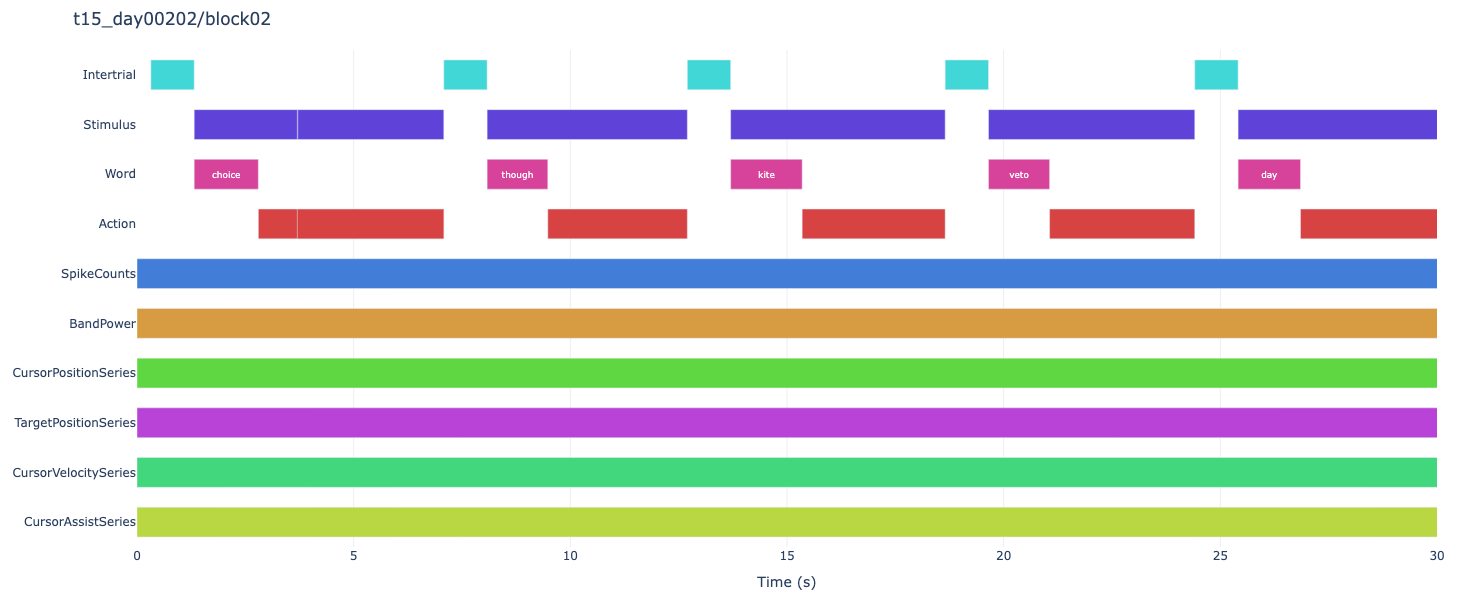

In [5]:
fig = viz.plot_events(block, lanes=LANES, label=label)
fig.update_xaxes(range=[0, 30])
fig

## 3. Select an event from Python

Clicking is only one input mechanism. `select_event` accepts the same stable event id stored in the plot's `customdata`, which is handy for tutorials, tests, and coordination with other widgets. Set `show_controls=False` when embedding a compact explorer controlled from Python.

In [6]:
word_id = int(np.flatnonzero(block.type.to_numpy() == "Word")[0])
word_explorer = viz.explore_events(
    block, lanes=LANES, label=label, show_controls=False
)
word_explorer.select_event(word_id)
word_explorer

    'data': [{'base': array([2.8, 3.7, 9.48, 15.35…

The registry resolves views by event-class inheritance. A `Word` therefore gets its specialized text view while retaining the generic fields view available to every event.

In [7]:
word = etypes.Event.from_dict(block.iloc[word_id].to_dict())
registry = viz.default_event_view_registry()
[(view.name, view.label, view.event_class.__name__) for view in registry.views_for(word)]

[('text', 'Text', 'BaseText'), ('fields', 'Fields', 'Event')]

## 4. Add a plot for one event type

A detail renderer is a function that receives an `EventViewContext` and returns an ipywidget, a Plotly figure, or another HTML-representable value. The context contains the selected row and typed event, the visible timeline range, labeled time references, a lazy data reader, and a `related(...)` helper for finding overlapping events.

Here an `Action` gets a new default view that overlays cursor and target trajectories during that action. This is the central extension pattern: register one or more named renderers for each event class, without adding event-specific branches to the explorer itself.

In [8]:
registry = viz.default_event_view_registry()

@registry.register(
    etypes.Action,
    name="cursor_trajectory",
    label="Cursor + target",
    default=True,
    time_sensitive=True,
)
def action_cursor_trajectory(ctx):
    related = ctx.related(("CursorPositionSeries", "TargetPositionSeries"))
    start, stop = ctx.display_window()
    figure = go.Figure()

    for _, row in related.iterrows():
        event = ctx.event_from_row(row)
        data = np.asarray(ctx.read(event))
        if data.ndim != 2 or data.shape[0] < 2:
            continue

        frequency = float(event.frequency)
        i0 = max(0, int(math.floor((start - event.start) * frequency)))
        i1 = min(
            data.shape[1],
            int(math.ceil((stop - event.start) * frequency)),
        )
        if i1 <= i0:
            continue
        times = event.start + np.arange(i0, i1) / frequency

        is_target = row["type"] == "TargetPositionSeries"
        figure.add_scatter(
            x=data[0, i0:i1],
            y=data[1, i0:i1],
            mode="lines",
            name=str(row["type"]),
            line={"dash": "dash" if is_target else "solid"},
        )
        for reference in ctx.time_references:
            if not start <= reference.time <= stop:
                continue
            index = int(np.argmin(np.abs(times - reference.time)))
            figure.add_scatter(
                x=[data[0, i0 + index]],
                y=[data[1, i0 + index]],
                mode="markers",
                marker={
                    "color": reference.color,
                    "size": 11,
                    "line": {"color": "white", "width": 1.5},
                },
                customdata=[times[index]],
                hovertemplate=(
                    f"{reference.id}: "
                    "%{customdata:.3f} s<extra></extra>"
                ),
                showlegend=False,
            )

    if not figure.data:
        return HTML("<i>No overlapping 2-D position streams.</i>")

    figure.update_layout(
        title=f"Movement during Action {start:.2f}–{stop:.2f} s",
        xaxis_title="x",
        yaxis_title="y",
        yaxis={"scaleanchor": "x", "scaleratio": 1},
        height=420,
    )
    return figure

In [9]:
action_mask = (block.type == "Action") & (block.duration.fillna(0) > 0)
action_id = int(np.flatnonzero(action_mask.to_numpy())[0])
action_row = block.iloc[action_id]
reference_times = [
    float(action_row.start + action_row.duration / 3),
    float(action_row.start + 2 * action_row.duration / 3),
]
custom_explorer = viz.explore_events(
    block,
    registry=registry,
    lanes=LANES,
    label=label,
    references=reference_times,
)
custom_explorer.select_event(action_id)
custom_explorer